# Notebook 09 — Deep Learning Data Pipeline

**Project:** Next Day Wildfire Spread Prediction via Tabular ML and Spatial Deep Learning  
**Team:** TensorTitans, Section C  
**Owners:** Riya and Tejas  
**Phase:** 2 (Deep Learning)  
**Objective:** Turn every TFRecord map into numpy arrays, build the 13 input channels (with wind as x/y vectors), fit the normalisation on train only, and check that flipping a map also flips the wind correctly.

---

## 1. Why Phase 2 needs a new pipeline
Phase 1 turned 30 maps into tabular rows and kept only 62 fire pixels. A CNN reads the whole 64×64 map at once, so here we keep **every map of every split** as an image. We store them once as `.npy` files so training does not re-read the TFRecords every epoch.

In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.dl_data as dd

raw_dir = "data/raw/archive"
data_dir = "data/processed/dl"
os.makedirs(data_dir, exist_ok=True)
os.makedirs("results/metrics", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)
os.makedirs("results/models", exist_ok=True)

for split in ["train", "eval", "test"]:
    if not os.path.exists(os.path.join(data_dir, f"{split}_X.npy")):
        print("converting", split)
        dd.convert_split(split, raw_dir, data_dir)
print(sorted(os.listdir(data_dir)))


['eval_X.npy', 'eval_Y.npy', 'test_X.npy', 'test_Y.npy', 'train_X.npy', 'train_Y.npy']


## 2. How much fire do we have now?
We count maps, fire pixels, no-fire pixels and unknown pixels (`-1`, cloud or missing data) in each split.

In [2]:
rows = []
for split in ["train", "eval", "test"]:
    Y = np.load(os.path.join(data_dir, f"{split}_Y.npy"))
    fire = int((Y == 1).sum())
    no_fire = int((Y == 0).sum())
    unknown = int((Y == -1).sum())
    rows.append({"split": split, "maps": len(Y), "fire_pixels": fire, "no_fire_pixels": no_fire,
                 "unknown_pixels": unknown, "fire_rate_percent": round(100 * fire / (fire + no_fire), 3)})

summary = pd.DataFrame(rows)
summary.to_csv("results/metrics/dl_data_summary.csv", index=False)
summary


,split,maps,fire_pixels,no_fire_pixels,unknown_pixels,fire_rate_percent
0,train,14979,658270,59254803,1440911,1.099
1,eval,1877,102594,7397791,187807,1.368
2,test,1689,84331,6643368,190445,1.253


## 3. Building the 13 input channels
Wind direction `th` is an angle, so 359° and 1° look far apart as numbers even though they are almost the same direction. `th` also gives the direction the wind comes **from**. We replace it with two wind vectors that point where the wind blows **to**:

- `wind_x = -vs × sin(th)` (east–west part, positive = blowing east)
- `wind_y = -vs × cos(th)` (north–south part, positive = blowing north)

We also keep wind speed `vs`. The `-1` values in `PrevFireMask` become 0, so the input only has 0 or 1 fire.

In [3]:
train_X, train_Y = dd.load_split(data_dir, "train")
print("train input shape:", train_X.shape, train_X.dtype)
print("channels:", dd.CHANNELS)


train input shape: (14979, 64, 64, 13) float16
channels: ['elevation', 'vs', 'wind_x', 'wind_y', 'tmmn', 'tmmx', 'sph', 'pr', 'pdsi', 'NDVI', 'population', 'erc', 'PrevFireMask']


## 4. Normalisation (fit on train only)
Each channel is clipped to its 0.1–99.9 percentile range (to remove extreme values) and then standardised to mean 0 and std 1. The numbers come **only from train**, the same leakage rule as Phase 1. `PrevFireMask` is left as 0/1.

In [4]:
norm = dd.fit_normalizer(train_X)
np.savez("results/models/unet_norm.npz", **norm)

norm_table = pd.DataFrame({"channel": dd.CHANNELS, "clip_low": norm["low"], "clip_high": norm["high"],
                           "mean": norm["mean"], "std": norm["std"]}).round(4)
norm_table.to_csv("results/metrics/dl_normalization.csv", index=False)
norm_table


,channel,clip_low,clip_high,mean,std
0,elevation,0.0000,3572.0000,899.507080,829.494019
1,vs,0.0000,9.5703,3.583600,1.297900
2,wind_x,-7.1797,7.6250,0.899300,2.709000
3,wind_y,-7.4258,7.7325,1.285600,2.164500
4,tmmn,0.0000,299.5000,281.734406,19.032101
5,tmmx,0.0000,315.2500,297.660309,20.029600
6,sph,0.0000,0.0187,0.006500,0.003700
7,pr,-0.1272,21.4219,0.330800,1.556900
8,pdsi,-5.8028,6.6484,-0.779500,2.431100
9,NDVI,-4380.0000,9288.0000,5294.625977,2196.713867


## 5. Looking at one training map

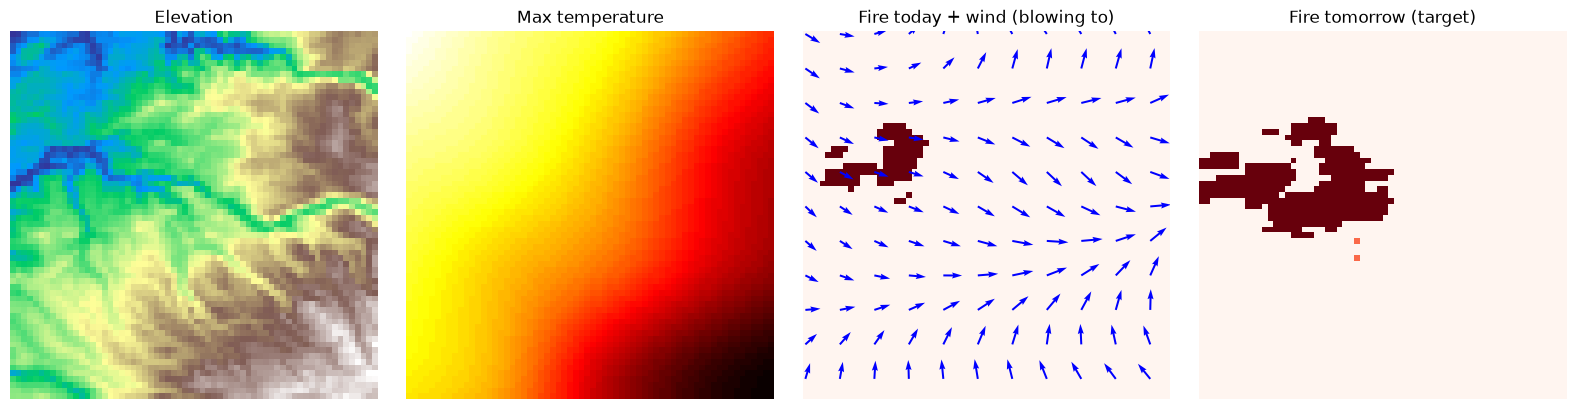

map index: 2838 fire pixels tomorrow: 339


In [5]:
fire_count = (train_Y == 1).sum(axis=(1, 2))
i = int(np.argsort(fire_count)[-200])
x = train_X[i].astype(np.float32)
y = train_Y[i]

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(x[..., 0], cmap="terrain")
ax[0].set_title("Elevation")
ax[1].imshow(x[..., 5], cmap="hot")
ax[1].set_title("Max temperature")
ax[2].imshow(x[..., 12], cmap="Reds", vmin=0, vmax=1)
step = 6
r, c = np.mgrid[0:64:step, 0:64:step]
ax[2].quiver(c, r, x[::step, ::step, 2], x[::step, ::step, 3], color="blue")
ax[2].set_title("Fire today + wind (blowing to)")
ax[3].imshow(np.where(y < 0, 0.5, y), cmap="Reds", vmin=0, vmax=1)
ax[3].set_title("Fire tomorrow (target)")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig("results/figures/dl_sample_map.png", dpi=150)
plt.show()
print("map index:", i, "fire pixels tomorrow:", int(fire_count[i]))


## 6. Augmentation check: flipping must also flip the wind
During training we randomly flip maps left–right and up–down to get more variety. If we flip the map left–right but not the wind, the wind would now blow the fire the wrong way. So a left–right flip also changes the sign of `wind_x`, and an up–down flip changes the sign of `wind_y`.

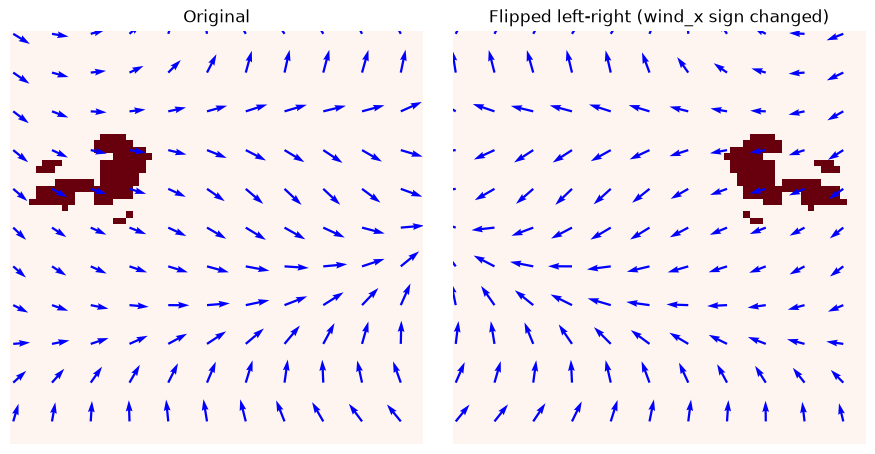

unknown pixels get weight 0: 2 of 4096


In [6]:
data = dd.FireData(train_X[i:i + 1], train_Y[i:i + 1], batch_size=1, augment=False)
x0, y0, w0 = data[0]
x_flip = x0[:, :, ::-1, :].copy()
x_flip[..., 2] = -x_flip[..., 2]

fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
for a, xx, title in [(ax[0], x0[0], "Original"), (ax[1], x_flip[0], "Flipped left-right (wind_x sign changed)")]:
    a.imshow(xx[..., 12], cmap="Reds", vmin=0, vmax=1)
    a.quiver(c, r, xx[::step, ::step, 2], xx[::step, ::step, 3], color="blue")
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.savefig("results/figures/dl_wind_flip_check.png", dpi=150)
plt.show()
print("unknown pixels get weight 0:", int((w0 == 0).sum()), "of", w0.size)


## 7. Summary
- All 18,545 maps are now used: **14,979 train**, **1,877 validation** and **1,689 test**.
- Train has **658,270 fire pixels**. Phase 1 trained on only 62.
- Fire is still rare: **1.10%** of known pixels in train, **1.37%** in validation and **1.25%** in test.
- 1,440,911 train pixels are unknown (`-1`). They get weight 0 in the loss, so they never count as "no fire".
- Wind is stored as two vectors pointing where the wind blows. In the sample map the fire grows towards the east and south-east, the same way the arrows point.
- Clip limits, means and standard deviations come from train only and are saved in `results/models/unet_norm.npz` and `results/metrics/dl_normalization.csv`.